# R2 · Calcul littéral et équations — solutions (notebook exécuté)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cemah2/workbookMaths/blob/main/chapitres/r2_calcul_litteral/05_solutions.ipynb)

Les réponses des exercices, exécutées. Les démarches détaillées (le *pourquoi*, les erreurs fréquentes, les variantes) sont dans `05_solutions.md`. Les cellules marquées `answer` enregistrent les réponses vérifiées par `wbm.check` (`tools/build_answers.py`).

| Partie | ID | Titre | Type | ★ | ⏱️ |
|---|---|---|---|---|---|
| 0 | R2.1 à R2.12, R2.16 | Les exercices papier (vérification) | ✏️ 🔗 | | |
| A | R2.22 | Vérifier développements et factorisations avec SymPy | 📦 | ★ | 15 |
|  | R2.27 | Chasse à l'erreur : six erreurs de calcul littéral | 🐛 | ★★ | 20 |
| B | R2.18 | Résoudre ax + b = 0 dans tous les cas · `solve_linear` | 🔨 | ★ | 25 |
|  | R2.19 | Résoudre ax + b ≤ 0 et rendre l'intervalle des solutions · `solve_linear_inequality` | 🔨 | ★★ | 40 |
|  | R2.20 | Résoudre \|x − a\| = c · `solve_abs_equation` | 🔨 | ★★ | 30 |
|  | R2.23 | Résoudre avec `sympy.solve` et lire son résultat | 📦 | ★ | 15 |
|  | R2.28 | Écrire un test pytest pour une fonction qui résout une équation | 🛠️ | ★ | 15 |
| C | R2.21 | Système 2 × 2 par la formule de Cramer · `solve_2x2` | 🔨 | ★★ | 40 |
|  | R2.26 | Un système, deux droites : voir la solution | 🎨 | ★★ | 20 |
|  | R2.24 | Prédire le nombre de solutions de trois systèmes, puis tracer leurs droites | 🔮 | ★ | 15 |
|  | R2.25 | Expérience : un système presque dégénéré, un coefficient bouge de 0,001 et la solution s'envole | 🔬 | ★★ | 20 |

In [1]:
# ⚙️ SETUP: run this cell first (on Colab or on your computer)
FAST_MODE = True  # True = quick version (a few seconds per cell); False = bigger experiments
SEED = 42

import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/cemah2/workbookMaths.git"
DRIVE_DIR = Path("/content/drive/MyDrive/workbookMaths")

try:
    import google.colab  # noqa: F401  (this module only exists on Colab)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    subprocess.run(["git", "config", "--global", "--add", "safe.directory", str(DRIVE_DIR)])
    if not (DRIVE_DIR / ".git").exists():
        subprocess.run(["git", "clone", REPO_URL, str(DRIVE_DIR)], check=True)
    else:
        # Get the new chapters. Your own work only lives in mon_travail/, which Claude never
        # touches, so "rebase + autostash" keeps it safe (even with local commits).
        identity = subprocess.run(["git", "-C", str(DRIVE_DIR), "config", "user.email"],
                                  capture_output=True).returncode == 0
        who = [] if identity else ["-c", "user.name=Workbook", "-c", "user.email=workbook@localhost"]
        pull = subprocess.run(["git", *who, "-C", str(DRIVE_DIR), "pull", "--rebase", "--autostash"],
                              capture_output=True, text=True)
        conflicts = subprocess.run(["git", "-C", str(DRIVE_DIR), "diff", "--name-only", "--diff-filter=U"],
                                   capture_output=True, text=True).stdout.split()
        if conflicts:  # a file changed outside mon_travail/ AND by Claude: git leaves conflict markers in it
            print("⚠️ Tes modifications de " + ", ".join(conflicts) + " (hors de mon_travail/) entrent en conflit "
                  "avec la nouvelle version ; elles sont gardées dans `git stash`. Pour reprendre la version du "
                  "dépôt : git restore --source=HEAD --staged --worktree <fichier> (00_setup/COLAB.md, « Problèmes "
                  "fréquents »).")
        elif pull.returncode != 0:
            print("⚠️ git pull a échoué (voir 00_setup/COLAB.md, « Problèmes fréquents ») :\n" + pull.stderr)
    ROOT = DRIVE_DIR
else:
    ROOT = Path(os.environ.get("WBM_ROOT", Path.cwd())).resolve()
    while not (ROOT / "src" / "wbm").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
    if not (ROOT / "src" / "wbm").exists():
        raise FileNotFoundError("Dépôt introuvable : ouvre ce notebook depuis le dossier de workbookMaths.")

os.environ["WBM_ROOT"] = str(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import wbm  # noqa: E402

cfg = wbm.setup(seed=SEED, fast=FAST_MODE)
FAST_MODE = cfg.fast
mymath = wbm.load_mymath("ref")  # reference implementation

🧪 workbookMaths : environnement
   Plateforme : Local (Linux x86_64, 2 CPU)
   Python 3.13.18 | numpy 2.1.3 | scipy 1.16.3 | sympy 1.14.0 | matplotlib 3.10.0 | pandas 2.2.3 | scikit-learn 1.6.1
   Graine : 42 | FAST_MODE : True


## Objectifs et rappel express

- Vérifier tes calculs papier (partie 0) : développer, factoriser, résoudre équations, inéquations, valeurs absolues et systèmes, mettre en équation.
- Écrire les quatre fonctions de `mymath/algebra.py` et les tester.
- Vérifier un calcul avec SymPy et savoir lire sa réponse ; voir les droites d'un système, et un système presque dégénéré.

**Rappel express.** $(a \pm b)^2 = a^2 \pm 2ab + b^2$ et $(a + b)(a - b) = a^2 - b^2$ ; $ax + b = 0$ a la solution $-\frac{b}{a}$ si $a \ne 0$ ; diviser une inéquation par un négatif retourne le sens ; $|x - a| = c$ donne $a \pm c$ si $c > 0$ ; un système 2 × 2 a une seule solution exactement quand $D = ad - bc \ne 0$.

## Partie 0 · Vérifier tes exercices papier (✏️ R2.1 à R2.12, 🔗 R2.16)

Fais d'abord les exercices de `02_exercices.md` **sur papier**, dans ta copie de `06_mes_reponses.md`. Reporte ensuite chaque réponse ici : **la valeur** que tu as trouvée, sous la forme indiquée en commentaire, jamais le calcul qui y mène :
- un nombre avec un point décimal, `-1.5` ; une fraction exacte entre guillemets, `"5/7"` ;
- une liste de coefficients, du plus haut degré au terme constant, zéros compris : `[2, 0, -5]` pour $2x^2 - 5$ ;
- une liste de solutions, dans l'ordre que tu veux, où une fraction s'écrit comme un calcul : `[-2/7, 6]` ;
- un intervalle entre guillemets, `"]-1 ; 4]"` ou `"[0 ; +oo["` ; une réunion avec un U ; l'ensemble vide avec le mot vide entre guillemets ;
- le nombre de solutions d'une équation ou d'un système, quand on te le demande, par son numéro : 1 pour aucune, 2 pour une seule, 3 pour une infinité.

Les réponses pas encore remplies affichent ⏳.

In [2]:
# Part 0: the answers are computed exactly from the statements
from fractions import Fraction

**Ex R2.1 — Substituer et réduire**

In [3]:
wbm.record("R2.1a", 2 * (-3) ** 2 - 3 * (-3) + 1, mistakes={"le carré d'un nombre négatif est positif : garde les parenthèses autour de −3": -8, "−3 × (−3) est positif : moins par moins donne plus": 10})
wbm.record("R2.1b", (2 - (-1)) ** 2 - 2 * (-1), mistakes={"a − b = 2 − (−1) : soustraire un négatif, c'est ajouter": 3, "ab est négatif : retirer un nombre négatif, c'est ajouter": 7})
wbm.record("R2.1c", [1, -2, 1], mistakes={"−x² compte en moins : 2x² − x²": [3, -2, 1], "réduis les termes en x avec leurs signes : 5x − 7x": [1, 12, 1], "les constantes se réduisent aussi, avec leurs signes : −3 + 4": [1, -2, -7]})
wbm.record("R2.1d", [7, 3], mistakes={"−2x + 5x : additionne les coefficients avec leurs signes": [7, -7], "l'ordre demandé est [coefficient de xy, coefficient de x]": [3, 7]})
wbm.record("R2.1e", (Fraction(1, 2) + 1) / (Fraction(1, 2) - 1), mistakes={"x − 1 est négatif pour x = 1/2 : le quotient aussi": 3})

WBM_ANSWER {"hash": "66d8da7f6063f4411bac27b13d743a8027fd1e2ec4fb17430b65194d773bbc89", "id": "R2.1a", "kind": "int", "magnitude": 1, "mistakes": {"0c216cf21b4e74491a0c6bf4f96d215e48bdf8990dac508bf698577b0977663c": "−3 × (−3) est positif : moins par moins donne plus", "a2155a354d2d45b42ae621711bb62ef2df75941cbaaf3ec2f19974d105812b23": "le carré d'un nombre négatif est positif : garde les parenthèses autour de −3"}, "sign": 1}
📝 Ex R2.1a : réponse enregistrée (int).
WBM_ANSWER {"hash": "315caf8eeca1a7b13fbd552addcb2211d0a18edeb54b8ba00fd1177cdbfa14dd", "id": "R2.1b", "kind": "int", "magnitude": 1, "mistakes": {"28086d2963ecac5d4f8c4e6786368d73edaa59193a69ef501a36d8453150a7e7": "ab est négatif : retirer un nombre négatif, c'est ajouter", "ac8ed5cf1b6541a673adb7990eec668f3252ede6fd2440c959757e99204321fa": "a − b = 2 − (−1) : soustraire un négatif, c'est ajouter"}, "sign": 1}
📝 Ex R2.1b : réponse enregistrée (int).
WBM_ANSWER {"decimals": 0, "element_hashes": ["1fc7c0359f7eab80ac55415cb193

**Ex R2.2 — Développer**

In [4]:
wbm.record("R2.2a", [2, -11], mistakes={"un moins devant une parenthèse change le signe de chacun de ses termes : −4 × (−1)": [2, -19], "−4 × x est négatif": [10, -11]})
wbm.record("R2.2b", [3, -1, -10], mistakes={"quatre produits : n'oublie pas les deux produits croisés": [3, 0, -10], "−2 × 3x est négatif": [3, 11, -10], "−2 × 5 est négatif": [3, -1, 10]})
wbm.record("R2.2c", [2, -1, 5, 3], mistakes={"trois termes dans la seconde parenthèse : six produits en tout": [2, -2, 6, 3]})
wbm.record("R2.2d", [-1, 3, 4], mistakes={"le signe moins devant porte sur tout le produit": [1, -3, -4], "le signe moins change le signe de chaque terme du produit développé, pas seulement du premier": [-1, -3, -4]})
wbm.record("R2.2e", [1, 1, -2], mistakes={"a × (−b) est négatif": [1, 3, -2], "n'oublie pas les produits croisés": [1, 0, -2]})

WBM_ANSWER {"decimals": 0, "element_hashes": ["5c1ebfa7f7086d99fc4df3f7f64a809f6c58f7dd00ce143466e50a4d6c601b75", "f8272f1761e65cc1bb347e514693c18c9c17f74e1f7a8276a7f92e994e12a161"], "hash": "a91844f9c8735bbb759dd2f01fe5cdc49fdbbfbe8f44a38ae3d3e118f58ac2b8", "id": "R2.2a", "integer": true, "kind": "array", "mistakes": {"112a281b2c3963d5146ee1444d6ec9e5a4b2390ac2ab3df2920d6df9749590b6": "un moins devant une parenthèse change le signe de chacun de ses termes : −4 × (−1)", "d524d4846a2c264768e8e70a620c92473bf8f78b80148485e295bbc62d5223f9": "−4 × x est négatif"}, "shape": [2]}
📝 Ex R2.2a : réponse enregistrée (array, 0 décimale(s)).
WBM_ANSWER {"decimals": 0, "element_hashes": ["2668f0ae248fc0f969acbfd3f5fee64e20c2296365755acda6a2ba6cd2dced9a", "833a2fb8a676482f9bb393670595f79835f61fe51c29ab90242459709a619ad2", "43b7e71300dcc3278be8d081ee9b1e746ceb082966a3745e6ee10572a15873aa"], "hash": "dd79dc94c79d7b963cafc8ab1d3d27de50a545986482192bc8dfb7d1bfca2dc7", "id": "R2.2b", "integer": true, "kin

**Ex R2.3 — Factoriser par un facteur commun**

In [5]:
wbm.record("R2.3a", [3, 2, 5], mistakes={"cherche le plus grand facteur commun : le PGCD des coefficients et la plus petite puissance de x": [1, 6, 15]})
wbm.record("R2.3b", [-2, 3], mistakes={"garde le signe de chaque terme en divisant par 4x": [2, 3], "divise chaque terme par 4x, coefficient compris": [-8, 12]})
wbm.record("R2.3c", [3, -2], mistakes={"additionne les deux parenthèses en gardant le signe de −5": [3, 8]})
wbm.record("R2.3d", [1, 5], mistakes={"le moins devant (x − 4) change aussi le signe de −4": [1, -3], "le second produit est soustrait : (2x + 1) − (x − 4)": [3, -3]})
wbm.record("R2.3e", [5, -3], mistakes={"le −3 garde son signe": [5, 3]})
wbm.record("R2.3f", [1, 1], mistakes={"le terme x − 7 vaut 1 × (x − 7) : il reste un 1, pas un 0": [1, 0]})

WBM_ANSWER {"decimals": 0, "element_hashes": ["10922c1e8723c974d541ce738b5b2a0d1c33e9ab9cda5f014f2848aea9487d97", "92b6662f2a18779699a19a9f0b4a81b773408a455c03f480d7e93a8ee2bcb386", "77250f31fb14393e1780d271830c2629183307bd6d6e60d0870e9b410daab0b8"], "hash": "9d1b219b7a59f08631df99a3129933185a3b02e9b858ff7bd13dec348fbf0211", "id": "R2.3a", "integer": true, "kind": "array", "mistakes": {"84f3c45d310b5ff8d6472bac6530a9eeca940f8e5b850d2a659332f331891203": "cherche le plus grand facteur commun : le PGCD des coefficients et la plus petite puissance de x"}, "shape": [3]}
📝 Ex R2.3a : réponse enregistrée (array, 0 décimale(s)).
WBM_ANSWER {"decimals": 0, "element_hashes": ["b0e7a49f0d536870005c88193adee536a762813b4903f1b8733b8c5972fe5fd1", "c27d7cd2282ceca2bf68c9ba19b82ef5e70bd3d68ace710a742e6b9fc7be8ec6"], "hash": "d99ef48047af14b135ab7a63d848a990fa9594f0b0de531e53516b37bea32ac1", "id": "R2.3b", "integer": true, "kind": "array", "mistakes": {"0a3fa1d0b040bd00afd34badfc3d37b5522d2aa6f20d0869a

**Ex R2.4 — Identités remarquables dans les deux sens**

In [6]:
wbm.record("R2.4a", [1, 10, 25], mistakes={"il manque le double produit 2ab": [1, 0, 25], "le double produit vaut 2 × a × b": [1, 5, 25]})
wbm.record("R2.4b", [9, -24, 16], mistakes={"le carré porte sur tout 3x": [3, -24, 16], "le double produit vaut 2 × a × b": [9, -12, 16], "(a − b)² n'est pas a² − b² : il y a un double produit": [9, 0, -16], "(a − b)² a un double produit négatif": [9, 24, 16], "il manque le double produit −2ab": [9, 0, 16]})
wbm.record("R2.4c", [4, 0, -49], mistakes={"(a + b)(a − b) = a² − b² : une différence": [4, 0, 49], "le carré porte sur tout 2x": [2, 0, -49]})
wbm.record("R2.4d", 7, mistakes={"développe (x − a)² : le double produit −2ax doit redonner le terme en x": -7, "le double produit vaut 2a, pas a": 14, "a² est le terme constant : il reste à prendre la racine": 49})
wbm.record("R2.4e", [5, 3], mistakes={"α² et β² sont les carrés : prends leurs racines carrées": [25, 9]})
wbm.record("R2.4f", [2, 5], mistakes={"α² et β² sont les carrés : prends leurs racines carrées": [4, 25]})
wbm.record("R2.4g", 101 ** 2, mistakes={"il manque le double produit": 10001})
wbm.record("R2.4h", 59 * 61, mistakes={"(a − b)(a + b) = a² − b² : on soustrait b², on ne l'ajoute pas": 3601, "a² seul n'est pas le résultat : (a − b)(a + b) = a² − b², il reste à soustraire b²": 3600})

WBM_ANSWER {"decimals": 0, "element_hashes": ["096df4c4a48ad3d5b113ac66007eb573c1952ecc5356e48183528816e5b685db", "ac37796f4fa4e02b28060471372a5a87b03d53a0b30a542eeb327f2ff7d68ceb", "2faca09c48dc3c352e2e07b421c38c9a2374c235002457cc335d3f2529e760b6"], "hash": "6bbefc68cb6f256e59adccdbe8ec68adf252cadf7af7411dda190af2c0b812fc", "id": "R2.4a", "integer": true, "kind": "array", "mistakes": {"08e3eaab82251195122be112e5a7cfce199a6c8d1841cae2356154d42d215db0": "il manque le double produit 2ab", "f5206bb2b3af060186ad5fca90ea1d8706483a46683fa59d77e481fb57ed743a": "le double produit vaut 2 × a × b"}, "shape": [3]}
📝 Ex R2.4a : réponse enregistrée (array, 0 décimale(s)).
WBM_ANSWER {"decimals": 0, "element_hashes": ["069cd5d335204e50a32a32c0818d66f9451fd03bc5ce2cc344071b0433d9b121", "5da52400cbaee606738b2ce62cf68b9eb3441526038d404afa386b98e1a53727", "8f5f55ec7e6bd649b598eb74fc6d21ecd03f9f4276805c5920379ff51747b6cf"], "hash": "b431f19abcf23fa602c6a2cf6270a064eeea227724a358dc9f0fe6ad954e7dc1", "id":

**Ex R2.5 — Équations du premier degré**

In [7]:
wbm.record("R2.5a", -2.0, decimals=2, mistakes={"pour isoler 4x, retire 9 aux deux membres": 2.5, "divise par 4 en gardant le signe": 2.0})
wbm.record("R2.5b", -3, mistakes={"retire 3x aux deux membres : −2x − 3x": 15, "divise par −5 en gardant le signe": 3})
wbm.record("R2.5c", 13, mistakes={"développe : le 3 multiplie les deux termes de la parenthèse": 9, "développe les deux parenthèses : chaque facteur multiplie tous les termes de la sienne": 5, "un terme qui change de membre change de signe": 1})
wbm.record("R2.5d", 18, mistakes={"le 2 multiplie tout le numérateur x + 4 : mets des parenthèses": 10, "le −1 aussi est multiplié par le dénominateur commun": 13})
wbm.record("R2.5e", 1, choices=[1, 2, 3], mistakes={"les x disparaissent : l'égalité qui reste est-elle vraie ?": 3, "les x disparaissent : il ne reste aucune valeur de x à trouver": 2})
wbm.record("R2.5f", 3, choices=[1, 2, 3], mistakes={"les x disparaissent : l'égalité qui reste est-elle vraie ou fausse ?": 1, "les x disparaissent : il ne reste aucune valeur de x à trouver": 2})

WBM_ANSWER {"decimals": 2, "hash": "48d4e1c4b462b6b124e4c3c76ba865312b80c61e32c60ee09ae3c1c8e7f6f76b", "hash_coarse": "0979b5d10f4da947850743c6a9a271ddc79ce2be1bb418ef9fda9168741a4367", "id": "R2.5a", "kind": "float", "magnitude": 0, "mistakes": {"0d29a1249c050219b998ffe4001a9ce26f7a38266629ce64995a49aa4668d1ce": "divise par 4 en gardant le signe", "a9bad7055e5abb737df23b5d2f424dfbdcd591be871fcdc8048e2bfa30430ab7": "pour isoler 4x, retire 9 aux deux membres"}, "sign": -1}
📝 Ex R2.5a : réponse enregistrée (float, 2 décimale(s)).
WBM_ANSWER {"hash": "f9e850a5c0d112ab97048f820666cfad078cc83ab45bc9c2e74ea5e61e3fdb52", "id": "R2.5b", "kind": "int", "magnitude": 0, "mistakes": {"06d2e74a9ede7667923403f58718b29e8cc2d3a8361a963dc30df79152c3b9c2": "retire 3x aux deux membres : −2x − 3x", "afe3dc71561049e4eab177c4133d0cef7409abdfbbd272d916f7a98b59b3ff38": "divise par −5 en gardant le signe"}, "sign": -1}
📝 Ex R2.5b : réponse enregistrée (int).
WBM_ANSWER {"hash": "2059b2b781d204f50ae843f4b9f088f

**Ex R2.6 — Équations produit nul et équations avec des fractions**

In [8]:
wbm.record("R2.6a", [4, -1.5], ordered=False, decimals=6, mistakes={"2x + 3 = 0 donne une solution négative": [4, 1.5], "2x = −3 : divise par 2": [4, -3]})
wbm.record("R2.6b", [0, 9 / 4], ordered=False, decimals=6, mistakes={"en divisant par x, on perd une solution : factorise": [9 / 4], "pour isoler x dans ax = b, on divise b par a, pas l'inverse": [0, 4 / 9]})
wbm.record("R2.6c", [1 / 3], ordered=False, decimals=6, mistakes={"pour isoler x dans ax = b, on divise b par a, pas l'inverse": [3], "un carré est nul seulement quand le nombre élevé au carré est nul : une seule solution": [-1 / 3, 1 / 3], "donne la valeur exacte, une fraction tapée comme un calcul, pas une valeur arrondie à deux décimales": [0.33], "donne la valeur exacte, une fraction tapée comme un calcul, pas une valeur arrondie à trois décimales": [0.333]})
wbm.record("R2.6d", [-4 / 3, 4 / 3], ordered=False, decimals=6, mistakes={"un carré égal à un nombre positif : deux solutions opposées": [4 / 3], "x² est connu : il reste à prendre la racine carrée": [-16 / 9, 16 / 9], "donne la valeur exacte, une fraction tapée comme un calcul, pas une valeur arrondie à deux décimales": [-1.33, 1.33], "donne la valeur exacte, une fraction tapée comme un calcul, pas une valeur arrondie à trois décimales": [-1.333, 1.333]})
wbm.record("R2.6e", 1, mistakes={"une valeur interdite annule un dénominateur": -2})
wbm.record("R2.6f", [5 / 2], ordered=False, decimals=6, mistakes={"3 multiplie tout le dénominateur : 3(x − 1)": [3 / 2]})
wbm.record("R2.6g", [8], ordered=False, decimals=6, mistakes={"le moins devant la fraction porte sur tout le numérateur x − 2": [16]})

WBM_ANSWER {"decimals": 6, "hash": "5c62bc36429ed6ff977e334f30c529cc0f64559bdec32530a826ffd395a89c8f", "id": "R2.6a", "kind": "set", "mistakes": {"7957119a4ad2dfd9011aede89c9d8b78b9896e2b1ac8c7e856711544b4906ec4": "2x = −3 : divise par 2", "b8e6ebed639c69c9f38fea6e06a644a92e5f76d3a3fd811b2ec2a9650df90b69": "2x + 3 = 0 donne une solution négative"}}
📝 Ex R2.6a : réponse enregistrée (set, 6 décimale(s)).
WBM_ANSWER {"decimals": 6, "hash": "fc571e3b4085471e6f7d6b8894999b81649993395a8dbba45410a2bdb20325cf", "id": "R2.6b", "kind": "set", "mistakes": {"94f0a24b7fff255607563c88de8eda67273eb48389d39d876312e38341a2e185": "pour isoler x dans ax = b, on divise b par a, pas l'inverse", "f4c734e01b8f1cd7b47d8d16910300e329466a37953f3cfedef05994883bc840": "en divisant par x, on perd une solution : factorise"}, "set_rounded": {"1": "65264e682c41d95724766c8500512b7b640a3c9c51a76b6dc72b7d20abcd3f3a"}}
📝 Ex R2.6b : réponse enregistrée (set, 6 décimale(s)).
WBM_ANSWER {"decimals": 6, "hash": "5f90dc281b7b

**Ex R2.7 — Inéquations et intervalles**

In [9]:
wbm.record("R2.7a", "]-oo ; 6[", kind="interval", mistakes={"l'inégalité est stricte : la borne est exclue": "]-oo ; 6]", "pour isoler 2x, ajoute 7 aux deux membres": "]-oo ; -1["})
wbm.record("R2.7b", "]-oo ; -3]", kind="interval", mistakes={"diviser par un nombre négatif retourne le sens": "[-3 ; +oo[", "l'inégalité est large : la borne est incluse": "]-oo ; -3["})
wbm.record("R2.7c", "[3 ; +oo[", kind="interval", mistakes={"diviser par un nombre négatif retourne le sens": "]-oo ; 3]", "l'inégalité est large : la borne est incluse": "]3 ; +oo["})
wbm.record("R2.7d", "]-3 ; 3]", kind="interval", mistakes={"chaque borne garde son inégalité : stricte à gauche, large à droite": "[-3 ; 3["})
wbm.record("R2.7e", "]-12 ; +oo[", kind="interval", mistakes={"le 2 multiplie tout le numérateur x − 3": "]-9 ; +oo["})

WBM_ANSWER {"hash": "ab6492e02bb846b15bbd14af007516156bc37c4d7984614b82777c1a7a6ee449", "id": "R2.7a", "kind": "interval", "mistakes": {"951be69b36145cdd405a3493da04079802d1ed41e53e908459bb12a4fb70d8af": "pour isoler 2x, ajoute 7 aux deux membres", "bd7ab1e3714dcfd919d1cbf5970a7c70fdea01bc6ca87ac528e8ee538668926e": "l'inégalité est stricte : la borne est exclue"}}
📝 Ex R2.7a : réponse enregistrée (interval).
WBM_ANSWER {"hash": "b4247c63be541b1ac9e38943a4992bc8ac78388266949eee87b760c53f563728", "id": "R2.7b", "kind": "interval", "mistakes": {"8b9c87d4a6c1f4a8bc3ff703034dafb4e3dce9facb3c87dcaf7cc11f2cbafea7": "diviser par un nombre négatif retourne le sens", "a591d80f7100a782e70f55b7e67c1f4e7ba93841d3d04208897d4ad20f327197": "l'inégalité est large : la borne est incluse"}}
📝 Ex R2.7b : réponse enregistrée (interval).
WBM_ANSWER {"hash": "b209db14f1c0e5b43c598245ef544b3040b39e45fb27a5e83e339a07a917b113", "id": "R2.7c", "kind": "interval", "mistakes": {"3b4b7c3d0324163972df6f4201e079dc668

**Ex R2.8 — Réunion et intersection d'intervalles**

In [10]:
wbm.record("R2.8a", "[1 ; 5]", kind="interval", mistakes={"∩ garde les nombres qui sont dans les deux à la fois (la réunion, c'est ∪)": "[-2 ; 8]"})
wbm.record("R2.8b", "[0 ; 3[", kind="interval", mistakes={"un nombre exclu de l'un des deux intervalles n'est pas dans l'intersection": "[0 ; 3]", "∩ garde les nombres qui sont dans les deux à la fois (la réunion, c'est ∪)": "]-oo ; +oo["})
wbm.record("R2.8c", "[-4 ; 6[", kind="interval", mistakes={"∪ garde les nombres qui sont dans l'un ou dans l'autre (l'intersection, c'est ∩)": "[0 ; 1]", "les deux intervalles se chevauchent : écris leur réunion en un seul intervalle": "[-4 ; 1] U [0 ; 6["})
wbm.record("R2.8d", "vide", kind="interval", mistakes={"l'intersection garde seulement les nombres communs aux deux": "]-oo ; -1] U [2 ; +oo["})
wbm.record("R2.8e", "]-oo ; -2[ U [3 ; +oo[", kind="interval", mistakes={"« ou » donne une réunion, pas une intersection": "vide", "x ≥ 3 : la borne 3 est incluse": "]-oo ; -2[ U ]3 ; +oo["})
wbm.record("R2.8f", "]2 ; 5[", kind="interval", mistakes={"« et » donne une intersection, pas une réunion": "]-oo ; +oo[", "2x > 4 : divise par 2": "]4 ; 5["})

WBM_ANSWER {"hash": "9dfc15ab464d898a6bb5c02bf2d37a342c06ebb56b6bd8d4f44b2f95f5825725", "id": "R2.8a", "kind": "interval", "mistakes": {"2ec45fd860332fccbe579e20ab63ad12a90f5d8dbf77d76246dcdef94470b879": "∩ garde les nombres qui sont dans les deux à la fois (la réunion, c'est ∪)"}}
📝 Ex R2.8a : réponse enregistrée (interval).
WBM_ANSWER {"hash": "9a2fdfdc58dd7954984b2fbe6ee16525d8872d7fea8bc8fd2f5ad2ff4fddc977", "id": "R2.8b", "kind": "interval", "mistakes": {"3202da8849847d2c7c7fd17042ae3e7c6924b2abaea69a002d7b5c5902192bfb": "un nombre exclu de l'un des deux intervalles n'est pas dans l'intersection", "39b0345bdd63a50cd3f689cc2fe34d1331ffeb811847dc7c900a84e71087b8a6": "∩ garde les nombres qui sont dans les deux à la fois (la réunion, c'est ∪)"}}
📝 Ex R2.8b : réponse enregistrée (interval).
WBM_ANSWER {"hash": "c61896c28251735acd6408d9f28eb5ba5c7339c3ff0394c87c2ae016ac1d6a17", "id": "R2.8c", "kind": "interval", "mistakes": {"3e231cfccd48f79f41d722691931af1313722a37f8d851840c8088746bd73

**Ex R2.9 — Équations et inéquations avec une valeur absolue, et la fonction signe**

In [11]:
wbm.record("R2.9a", [-1, 7], ordered=False, mistakes={"une distance donnée à un point : deux solutions, une de chaque côté": [7], "|x − 3| est la distance de x à 3, pas à −3": [-7, 1]})
wbm.record("R2.9b", [-5, 4], ordered=False, mistakes={"deux cas : 2x + 1 = 9 ou 2x + 1 = −9": [4]})
wbm.record("R2.9c", [], ordered=False, mistakes={"une valeur absolue est une distance : elle n'est jamais négative": [4, 8]})
wbm.record("R2.9d", "[-4 ; 2]", kind="interval", mistakes={"x + 1 = x − (−1) : c'est la distance de x à −1": "[-2 ; 4]", "≤ : les points à distance au plus 3, donc entre les deux": "]-oo ; -4] U [2 ; +oo["})
wbm.record("R2.9e", "]-oo ; -3[ U ]7 ; +oo[", kind="interval", mistakes={"> : les points à distance plus grande que 5, donc à l'extérieur": "]-3 ; 7[", "l'inégalité est stricte : les bornes sont exclues": "]-oo ; -3] U [7 ; +oo["})
wbm.record("R2.9f", Fraction(13, 2), kind="fraction", mistakes={"la distance entre a et b est |a − b| : soustrais avec les signes": "5/2"})
wbm.record("R2.9g", -1, mistakes={"(−2)² − 9 est négatif": 1, "sign ne donne que −1, 0 ou 1": -5})

WBM_ANSWER {"hash": "ceca8227e887e10e656230268f6ed46fc115da9866fdd7b1cbfc19dd1255f44c", "id": "R2.9a", "kind": "set", "mistakes": {"afc1e7e77ea6166bf0fcdd178fdde686669ad27c3a50d23007acb6c01f06977e": "une distance donnée à un point : deux solutions, une de chaque côté", "da642b9c93cf7ea01f66fb223a479e18ed4fa08c95cc69a4f8eb367849a045c1": "|x − 3| est la distance de x à 3, pas à −3"}}
📝 Ex R2.9a : réponse enregistrée (set).
WBM_ANSWER {"hash": "c3ea8bfa3f6bf4be814eb87a45b4510a69d906a43c426998d3070350ae3f4384", "id": "R2.9b", "kind": "set", "mistakes": {"9d20d4a2770aa95380b7c42dc8dded90c574ffbb64e92b47b9a8268e5e8d179a": "deux cas : 2x + 1 = 9 ou 2x + 1 = −9"}}
📝 Ex R2.9b : réponse enregistrée (set).
WBM_ANSWER {"hash": "a7f3346aed7e58e98b9a838a66d9ad4759ee900c3753b27dab470123d6f9951c", "id": "R2.9c", "kind": "set", "mistakes": {"6654b1a969f46847e094c847b97c7e80e19b5226fabc901ff3de0518fc1da560": "une valeur absolue est une distance : elle n'est jamais négative"}}
📝 Ex R2.9c : réponse enregi

**Ex R2.10 — Système 2 × 2 par substitution et par combinaison**

In [12]:
wbm.record("R2.10a", [2, 3], mistakes={"l'ordre demandé est [x, y]": [3, 2]})
wbm.record("R2.10b", [1, -2], mistakes={"l'ordre demandé est [x, y]": [-2, 1]})
wbm.record("R2.10c", [2, -3], mistakes={"l'ordre demandé est [x, y]": [-3, 2]})
wbm.record("R2.10d", [6, 3], mistakes={"l'ordre demandé est [x, y]": [3, 6]})

WBM_ANSWER {"decimals": 0, "element_hashes": ["567fd5dfe6a24b968348b1d82a980c6ea8e729d73ae1b0ec1a935cd8832a60fa", "e36fdab79ada30364bd36cb39d0cdb36ab0193ead09c47d84c8f689213094889"], "hash": "ceca1e9e43cefb7853331c47ebbdb278dd6c920b18de5ced7d1acf4d6f3ff9d9", "id": "R2.10a", "integer": true, "kind": "array", "mistakes": {"d90bfbfef7e246541bf54e7fdf5aa8e0b01257919d12f4037d4144178ad14e5d": "l'ordre demandé est [x, y]"}, "shape": [2]}
📝 Ex R2.10a : réponse enregistrée (array, 0 décimale(s)).
WBM_ANSWER {"decimals": 0, "element_hashes": ["4ac08270307b5d7af2e11f1eda26f4807e6191ae9602dc2d9cf6fa1fa316d1d7", "30b03a48538c12be12f68db427f179095e9650860292569290d92dba9575c692"], "hash": "c0c9288420bb55f5c7150d002d707885474c23b4fd36d0c06eec7619ae19ff35", "id": "R2.10b", "integer": true, "kind": "array", "mistakes": {"cce1eaf8cd0b4bac09bee82a1b6c69da2f2eb2b9b112680932b597f6e8aea563": "l'ordre demandé est [x, y]"}, "shape": [2]}
📝 Ex R2.10b : réponse enregistrée (array, 0 décimale(s)).
WBM_ANSWER {"d

**Ex R2.11 — Système 2 × 2 par la formule de Cramer**

In [13]:
wbm.record("R2.11a", 2 * (-1) - 5 * 3, mistakes={"D = ad − bc : le produit bc est soustrait": 13, "d vaut −1 : garde son signe": -13})
wbm.record("R2.11b", [3, -1], mistakes={"l'ordre demandé est [x, y]": [-1, 3], "divise par D en gardant son signe": [-3, 1]})
wbm.record("R2.11c", 3, choices=[1, 2, 3], mistakes={"compare aussi les seconds membres : la seconde équation est-elle un multiple de la première, membre de droite compris ?": 1, "le déterminant est nul : pas une seule solution": 2})
wbm.record("R2.11d", 1, choices=[1, 2, 3], mistakes={"compare les seconds membres : sont-ils dans le même rapport que les coefficients ?": 3, "le déterminant est nul : pas une seule solution": 2})

WBM_ANSWER {"hash": "e154eaaf4a01432fd7b9af57fa96feeef80675d1eaff622f09f40983bf5ad0f6", "id": "R2.11a", "kind": "int", "magnitude": 1, "mistakes": {"024327bbf02e4b18af0e55ce14b001a047442f4e847244b95c131bd42dbfc9cd": "D = ad − bc : le produit bc est soustrait", "e2208232d3748f92657fa38d966390fd2202dd0bf2de338ce09bce1c18363ead": "d vaut −1 : garde son signe"}, "sign": -1}
📝 Ex R2.11a : réponse enregistrée (int).
WBM_ANSWER {"decimals": 0, "element_hashes": ["36e0031c73ec5944108327d5e2692b7cdc3870c494a867bfe4f323adcd93a3d4", "6f1b1be75fcc3f74e60f576166a5aef37151de4aa84c073039c5701d4850a11d"], "hash": "e9ffb9fff6c56a0608fe596d599929a6bf1686916efcf6809016ff85ba6e6df4", "id": "R2.11b", "integer": true, "kind": "array", "mistakes": {"69cfc43d19b3963490ce3f5d176792c147f0eedebf07b12bed9fa0b44543d38c": "l'ordre demandé est [x, y]", "fd2352ba17f854ffeeb5c9c2c3fe16c87290917a947ae478b2ef518087ce318f": "divise par D en gardant son signe"}, "shape": [2]}
📝 Ex R2.11b : réponse enregistrée (array, 0 dé

**Ex R2.12 — Mettre en équation : trois problèmes**

In [14]:
wbm.record("R2.12a", 8.0 * 15, decimals=2, mistakes={"le périmètre compte chaque côté deux fois : 2 × (longueur + largeur)": 516.75, "on demande l'aire, pas la longueur": 15.0, "on demande l'aire, pas la largeur": 8.0})
wbm.record("R2.12b", 56 / 0.8, decimals=2, mistakes={"la baisse porte sur le prix de départ, pas sur le prix réduit": 67.2, "le prix donné est déjà celui d'après la baisse : on cherche le prix d'avant": 44.8})
wbm.record("R2.12c", 10, mistakes={"c'est le nombre de tables de 4 places : relis la question": 12})

WBM_ANSWER {"decimals": 2, "hash": "ab86f7909c483fea7a248ebb5cca70baac2b1a3e3a4708636afb2b907479917e", "hash_coarse": "b478e11bf6856b76f726e309f47a85217dd305a1dcdbfeb95bd740e5955e2f7e", "id": "R2.12a", "kind": "float", "magnitude": 2, "mistakes": {"019840e2da197108158f21c5972f02119fee47d1d3d67cc341901a5f29d5438d": "on demande l'aire, pas la largeur", "7fc0c1809ea7888a5cc50e548245dacc1375e92f7ba421c6d15226f663bc0d66": "le périmètre compte chaque côté deux fois : 2 × (longueur + largeur)", "aa5446348eb35d8c725adfa7191dde5e66be52852e60394a03232522d601d747": "on demande l'aire, pas la longueur"}, "sign": 1}
📝 Ex R2.12a : réponse enregistrée (float, 2 décimale(s)).
WBM_ANSWER {"decimals": 2, "hash": "240a2d711a670313a8af80fcdb613933cbc51dda008a1c40ea0542e82c057430", "hash_coarse": "12683e3a03c52f4d8599650854021a026e127988a955ef16fb224c38f137e801", "id": "R2.12b", "kind": "float", "magnitude": 1, "mistakes": {"05920235c3f7f57e2519aaab234d339b1cb2d3dcef7886832a071543af1d567d": "la baisse port

**Ex R2.16 — Deux mesures, deux inconnues : retrouver a et b dans y = ax + b par un système**

In [15]:
wbm.record("R2.16a", [25.0, -8.0], decimals=3, mistakes={"l'ordre demandé est [a, b]": [-8.0, 25.0]})
wbm.record("R2.16b", 25 * 1.4 - 8, decimals=2, mistakes={"T = a × u + b : n'oublie pas b": 35.0})
wbm.record("R2.16c", 51.5 - (25 * 2.4 - 8), decimals=2, mistakes={"l'écart est la mesure moins la prédiction : son signe compte": 0.5, "on demande l'écart entre la mesure et la prédiction, pas la prédiction elle-même": 52.0})
wbm.record("R2.16d", 1, choices=[1, 2, 3], mistakes={"le point de la troisième mesure est-il sur la droite des deux premières ?": 2, "trois équations pour deux inconnues : une infinité seulement si elles disent toutes la même chose": 3})

WBM_ANSWER {"decimals": 3, "element_coarse": [["ffc02e4992c742110c2de6433af01421e89997d3e3abafabaa3e66a4bbfa869b"], ["b22e4b4a9ef367d45b2283c2767de427ba9d4529d460fc7140874236c8ac3c8e"]], "element_hashes": ["67eecf2e55b8591bf7027bd7b9131e6734543922d42cd5a3aa7840ebde80ba75", "b6c40e84358b5e3f74718f95481004b207db99b6f78a687c638c394c94d9c41b"], "hash": "2601ab94be509ba8ab91323d052f39952e3d34279035cab2b2c870f385b6fb68", "id": "R2.16a", "kind": "array", "mistakes": {"5fdb6d7f18cf621ccaad105822b6cbf9dac3372643b29738165177811bf07ea8": "l'ordre demandé est [a, b]"}, "shape": [2]}
📝 Ex R2.16a : réponse enregistrée (array, 3 décimale(s)).
WBM_ANSWER {"decimals": 2, "hash": "d3ee2d3f1d7fb9f43f0b4e77550300a75a4e4209e6fb12ee240333600c86774d", "hash_coarse": "c30d981a25a7c28dd3ac5d0e8903e6d23cb5bf2c2a435048c8b8bc18eade54cb", "id": "R2.16b", "kind": "float", "magnitude": 1, "mistakes": {"eedb010a08b78b418eb127ea7e3e8c20fcee26f32bfa2dd63ca5f469eab2cb76": "T = a × u + b : n'oublie pas b"}, "sign": 1}
📝 

## Partie A · Calcul littéral : vérifier avec SymPy, chasser les erreurs

Fiche §1 à §3. SymPy comme outil de vérification de tes calculs papier, et une chasse aux erreurs classiques du calcul littéral.

In [16]:
# Tools of the notebook (parts A to C)
import math
import traceback

import matplotlib.pyplot as plt
import numpy as np
import sympy as sp

from wbm.nbtools import checked, run_pytest_group

x, y = sp.symbols("x y")


def as_interval(result):
    """(left_closed, low, high, right_closed), or None, -> the interval text that wbm.check reads."""
    if result is None:
        return "vide"
    left, low, high, right = result
    ends = ["-oo" if v == -math.inf else "+oo" if v == math.inf else repr(float(v)) for v in (low, high)]
    return f"{'[' if left else ']'}{ends[0]} ; {ends[1]}{']' if right else '['}"


def raised(function, *args):
    """The name of the exception that function(*args) raises, or "aucune" if it returns.

    NotImplementedError (a TODO not done yet) goes through, for wbm.attempt to show ⏳."""
    try:
        function(*args)
    except NotImplementedError:
        raise
    except Exception as exc:  # noqa: BLE001 - any other error is the answer
        return type(exc).__name__
    return "aucune"

### Ex R2.22 — Vérifier développements et factorisations avec SymPy 📦 ★ ⏱️ 15 min
**Objectif :** développer, tester une égalité et factoriser avec SymPy, pour vérifier un calcul fait à la main.  
**Prérequis :** fiche §2 et §3 ; R0 §4 (SymPy) · **Parcours :** C, E

Les symboles `x` et `y` sont déjà créés (cellule des outils). Trois outils de SymPy :
- `sp.expand(e)` développe et réduit ; `sp.factor(e)` factorise ;
- `sp.Poly(e, x).all_coeffs()` donne la liste des coefficients d'un polynôme en $x$, du plus haut degré au terme constant (comme dans la partie 0) ;
- deux expressions $A$ et $B$ sont égales pour **tout** $x$ exactement quand `sp.expand(A - B)` vaut `0` : c'est une preuve, pas un test sur quelques valeurs.

Avec eux :
- a) développe $(3x - 2)(x^2 + 4x - 1)$, et donne la liste de ses coefficients ;
- b) parmi ces quatre égalités, lesquelles sont vraies pour tout $x$ ? Donne leurs lettres dans un texte.

| | Égalité |
|---|---|
| A | $(x - 3)^2 = x^2 - 9$ |
| B | $(2x + 1)^2 - (2x - 1)^2 = 8x$ |
| C | $(x + 1)^3 = x^3 + 3x^2 + 3x + 1$ |
| D | $(x + 2)(x^2 - 2x + 4) = x^3 + 4$ |

- c) factorise $x^2 + x - 12$, puis donne la liste des valeurs de $x$ qui l'annulent (fiche §4, équation produit nul).

Fais d'abord a) et c) à la main : SymPy est là pour vérifier.

In [17]:
expanded = sp.expand((3*x - 2)*(x**2 + 4*x - 1))
print("a)", expanded, "->", sp.Poly(expanded, x).all_coeffs())
claims = {"A": ((x - 3)**2, x**2 - 9),
          "B": ((2*x + 1)**2 - (2*x - 1)**2, 8*x),
          "C": ((x + 1)**3, x**3 + 3*x**2 + 3*x + 1),
          "D": ((x + 2)*(x**2 - 2*x + 4), x**3 + 4)}
for letter, (left, right) in claims.items():
    gap = sp.expand(left - right)
    print("b)", letter, "vraie" if gap == 0 else f"fausse : gauche − droite = {gap}")
print("c)", sp.factor(x**2 + x - 12), "->", sp.solve(x**2 + x - 12, x))
answer_R2_22a = sp.Poly(expanded, x).all_coeffs()
answer_R2_22b = "".join(letter for letter, (left, right) in claims.items() if sp.expand(left - right) == 0)
answer_R2_22c = sp.solve(x**2 + x - 12, x)

a) 3*x**3 + 10*x**2 - 11*x + 2 -> [3, 10, -11, 2]
b) A fausse : gauche − droite = 18 - 6*x
b) B vraie
b) C vraie
b) D fausse : gauche − droite = 4


c) (x - 3)*(x + 4) -> [-4, 3]


In [18]:
wbm.record("R2.22a", [3, 10, -11, 2],
           mistakes={"all_coeffs commence par le terme de plus haut degré": [2, -11, 10, 3],
                     "le terme en x vient de deux produits, chacun avec son signe": [3, 10, 5, 2]})
wbm.record("R2.22b", "BC",
           mistakes={"A est fausse : le carré d'une différence a un double produit": "ABC",
                     "D est fausse : développe le produit, puis regarde le terme constant": "BCD",
                     "B est vraie : développe l'écart gauche − droite, il vaut 0": "C",
                     "C est vraie : développe l'écart gauche − droite, il vaut 0": "B"})
wbm.record("R2.22c", [3, -4], ordered=False,
           mistakes={"un facteur x − a s'annule pour x = a, avec le signe opposé à celui de la parenthèse": [-3, 4]})

WBM_ANSWER {"decimals": 0, "element_hashes": ["656398c86b479bccfa8b2f4a0846f452385005e2431c9bc6f291c570d993fae7", "006171948bca63ca7d721e285b289a8085e98f5b23ba7025521286e47200ca5f", "22b14e485602673e0f172b2ab1432cc4127249bc25f04279e78aec423d8fecf8", "8de415e013c96c163a68e1c98b223e4858eb5bb6e71f8ae491b4a4ac5dec2f18"], "hash": "588fa9b53c41cce329fa8ec3c7b2b5d2112801891cd73e0e3cea557c60c57e8c", "id": "R2.22a", "integer": true, "kind": "array", "mistakes": {"3429bfce19ae8fcefce20c837b194b3d9ec727e8f5b12cee238673290e8c7038": "all_coeffs commence par le terme de plus haut degré", "a83be46dfb4f5d43d0f92c4299c2c14fe4e69acca10be956d6657817573d70b9": "le terme en x vient de deux produits, chacun avec son signe"}, "shape": [4]}
📝 Ex R2.22a : réponse enregistrée (array, 0 décimale(s)).
WBM_ANSWER {"hash": "845fce7618906f8b25be1279711d75add329674f6a64f7c08c48d657a5b45ee9", "id": "R2.22b", "kind": "str", "mistakes": {"1c232754a8e0a08682b278ad2d5a2cfbf1d9c33ace692fe4998c010e7109270f": "D est fausse :

💡 L'égalité D est fausse de peu : $(x + 2)(x^2 - 2x + 4) = x^3 + 8$, une identité « somme de deux cubes ». Essayer $x = 0$ suffit à la réfuter ($8 \ne 4$) ; un test réussi, lui, n'aurait rien prouvé.

### Ex R2.27 — Chasse à l'erreur : six erreurs de calcul littéral 🐛 ★★ ⏱️ 20 min
**Objectif :** repérer les erreurs classiques de calcul littéral, et les corriger.  
**Prérequis :** fiche §2 à §5, « Les pièges classiques » · **Parcours :** C, E

Un camarade a fait huit calculs. **Sans rien exécuter d'abord**, trouve les six qui sont faux.

| | Calcul |
|---|---|
| A | $(x - 5)^2 = x^2 - 25$ |
| B | $-(2x - 3) = -2x + 3$ |
| C | $(3x)^2 = 3x^2$ |
| D | $2(x + 4) - 3(x - 1) = -x + 5$ |
| E | $(x + 2)(x - 2) = x^2 - 4$ |
| F | $-4x < 10 \iff x < -2{,}5$ |
| G | $3x^2 = 6x \iff x = 2$ |
| H | $\dfrac{x + 1}{2} \times 4 = 2x + 1$ |

- a) Les lettres des calculs faux, dans un texte.
- b) Le bon résultat de D : la liste $[\alpha, \beta]$ de $\alpha x + \beta$.
- c) Le bon ensemble des solutions de l'inéquation de F, en intervalle.
- d) La bonne liste des solutions de l'équation de G.

Puis, si tu veux, confirme avec SymPy (`sp.expand`, `sp.solveset`) : la solution montre comment.

In [19]:
identities = {"A": ((x - 5)**2, x**2 - 25), "B": (-(2*x - 3), -2*x + 3), "C": ((3*x)**2, 3*x**2),
              "D": (2*(x + 4) - 3*(x - 1), -x + 5), "E": ((x + 2)*(x - 2), x**2 - 4),
              "H": ((x + 1) / 2 * 4, 2*x + 1)}
for letter, (left, right) in identities.items():
    print(letter, "juste" if sp.expand(left - right) == 0 else f"faux : le calcul donne {sp.expand(left)}")
print("F : faux, les solutions sont", sp.solve_univariate_inequality(-4*x < 10, x, relational=False))
print("G : faux, les solutions sont", sp.solveset(3*x**2 - 6*x, x, sp.S.Reals))

A faux : le calcul donne x**2 - 10*x + 25
B juste
C faux : le calcul donne 9*x**2
D faux : le calcul donne 11 - x
E juste
H faux : le calcul donne 2*x + 2
F : faux, les solutions sont Interval.open(-5/2, oo)
G : faux, les solutions sont {0, 2}


In [20]:
wbm.record("R2.27a", "ACDFGH",
           mistakes={"il manque une ligne fautive : le carré d'une différence qui a perdu son double produit": "CDFGH",
                     "il manque une ligne fautive : un carré qui ne porte pas sur tout le produit": "ADFGH",
                     "il manque une ligne fautive : un moins devant une parenthèse qui ne change pas tous ses signes": "ACFGH",
                     "il manque une ligne fautive : une division par un nombre négatif qui garde le sens": "ACDGH",
                     "il manque une ligne fautive : une équation divisée par l'inconnue": "ACDFH",
                     "il manque une ligne fautive : une fraction multipliée sans parenthèses autour de son numérateur": "ACDFG",
                     "une ligne de trop : la ligne (B) est correcte ; relis ce qu'elle fait": "ABCDFGH",
                     "une ligne de trop : la ligne (E) est correcte ; relis ce qu'elle fait": "ACDEFGH",
                     "la ligne (B) est correcte, et il manque une ligne fautive : le carré d'une différence qui a perdu son double produit": "BCDFGH",
                     "la ligne (E) est correcte, et il manque une ligne fautive : le carré d'une différence qui a perdu son double produit": "CDEFGH",
                     "la ligne (B) est correcte, et il manque une ligne fautive : un carré qui ne porte pas sur tout le produit": "ABDFGH",
                     "la ligne (E) est correcte, et il manque une ligne fautive : un carré qui ne porte pas sur tout le produit": "ADEFGH",
                     "la ligne (B) est correcte, et il manque une ligne fautive : un moins devant une parenthèse qui ne change pas tous ses signes": "ABCFGH",
                     "la ligne (E) est correcte, et il manque une ligne fautive : un moins devant une parenthèse qui ne change pas tous ses signes": "ACEFGH",
                     "la ligne (B) est correcte, et il manque une ligne fautive : une division par un nombre négatif qui garde le sens": "ABCDGH",
                     "la ligne (E) est correcte, et il manque une ligne fautive : une division par un nombre négatif qui garde le sens": "ACDEGH",
                     "la ligne (B) est correcte, et il manque une ligne fautive : une équation divisée par l'inconnue": "ABCDFH",
                     "la ligne (E) est correcte, et il manque une ligne fautive : une équation divisée par l'inconnue": "ACDEFH",
                     "la ligne (B) est correcte, et il manque une ligne fautive : une fraction multipliée sans parenthèses autour de son numérateur": "ABCDFG",
                     "la ligne (E) est correcte, et il manque une ligne fautive : une fraction multipliée sans parenthèses autour de son numérateur": "ACDEFG"})
wbm.record("R2.27b", [-1, 11],
           mistakes={"un moins devant une parenthèse change le signe de chacun de ses termes": [-1, 5],
                     "−3 × x est négatif": [5, 11]})
wbm.record("R2.27c", "]-2.5 ; +oo[", kind="interval",
           mistakes={"diviser par un nombre négatif retourne le sens": "]-oo ; -2.5[",
                     "la borne est le quotient de deux nombres de signes contraires : elle est négative":
                     "]2.5 ; +oo["})
wbm.record("R2.27d", [0, 2], ordered=False,
           mistakes={"en divisant par x, on perd une solution : factorise 3x² − 6x": [2]})

WBM_ANSWER {"hash": "2928bde8b701ee10c1f5ec160b2572d65db7ff0296f40fb44e204f608d1ba7a9", "id": "R2.27a", "kind": "str", "mistakes": {"2af69e6aadc4ba7843d4a8229f3ae91f09aed60b815a90bc0201681b531c1a0a": "la ligne (B) est correcte, et il manque une ligne fautive : une division par un nombre négatif qui garde le sens", "39b97952883fd2bebdc5210b68267706de4e8cee1f5e2155172050ee85783811": "la ligne (E) est correcte, et il manque une ligne fautive : le carré d'une différence qui a perdu son double produit", "3c5423a0177607d23918254b8ff09784fb2c4f9c78c98c65e5fc62c88ba05a05": "il manque une ligne fautive : une division par un nombre négatif qui garde le sens", "64265ece3572c134aac75d8b1372fcecef63a326082ce9caa9dcf28624aae044": "la ligne (E) est correcte, et il manque une ligne fautive : une fraction multipliée sans parenthèses autour de son numérateur", "6ee521af4911f2ec8b1312d217d6f650856e69f37558c5a73b55e5b3d1d16bd0": "la ligne (E) est correcte, et il manque une ligne fautive : un moins devant 

💡 Les deux calculs justes ont chacun leur piège apparent : B change bien les deux signes, et E est l'identité $(a + b)(a - b) = a^2 - b^2$. Pour H, le 4 multiplie tout le numérateur : $\frac{x + 1}{2} \times 4 = 2(x + 1) = 2x + 2$.

## Partie B · Équations et inéquations

Fiche §4 à §6. Trois fonctions de `mymath/algebra.py` (équation, inéquation, valeur absolue), SymPy et ses pièges, et un test que tu écris toi-même.

### Ex R2.18 — Résoudre ax + b = 0 dans tous les cas · `solve_linear` 🔨 ★ ⏱️ 25 min
**Objectif :** programmer la résolution de ax + b = 0, cas dégénérés compris.  
**Prérequis :** fiche §4, « L'équation ax + b = 0 » ; workbookIA 0A §100.4.2 · **mymath :** `algebra.py` · **Parcours :** C, E

> **Mode d'emploi `mymath`** (comme en R1). Ouvre ta copie `mon_travail/mymath/algebra.py`, lis la docstring du module **et** celle de la fonction en entier, remplace la ligne `raise NotImplementedError(...)` par ton code, **enregistre** le fichier, puis exécute les cellules ci-dessous : la première recharge ta librairie. N'utilise ni SymPy ni NumPy dans `algebra.py` : les tests s'en servent pour vérifier tes résultats.

Écris `solve_linear(a, b)` : les **trois cas** de la fiche (§4). Une solution se rend dans une liste, `[x]` (divise avec `/`, pour obtenir un flottant) ; aucune solution, la liste vide `[]` ; tous les réels, la chaîne `"all"`. Compare `a` (et `b`) à 0 avec `==` : les tests des cas dégénérés utilisent des entiers.

La vérification calcule `solve_linear(-5, 2)`, regarde si `solve_linear(0, -3)` vaut bien `[]` et si `solve_linear(0, 0)` vaut bien `"all"`, puis lance les tests.

In [21]:
mymath = wbm.load_mymath("ref")
for a, b in [(-5, 2), (0, -3), (0, 0)]:
    print(f"solve_linear({a}, {b}) =", mymath.algebra.solve_linear(a, b))

solve_linear(-5, 2) = [0.4]
solve_linear(0, -3) = []
solve_linear(0, 0) = all


In [22]:
wbm.record("R2.18a", [0.4], decimals=4,
           mistakes={"la solution de ax + b = 0 est −b/a : attention au signe": [-0.4],
                     "la solution est −b/a, pas −a/b": [2.5]})
wbm.record("R2.18b", True,
           mistakes={"0x − 3 = 0 n'est jamais vrai : la fonction doit rendre la liste vide, []": False})
wbm.record("R2.18c", True,
           mistakes={"0x + 0 = 0 est vrai pour tout x : la fonction doit rendre exactement la chaîne \"all\"": False})

WBM_ANSWER {"decimals": 4, "hash": "d67bd66ab14a48315fe263717f1d453b761fd392d79b5826dc74e9a62b1a042a", "id": "R2.18a", "kind": "array", "mistakes": {"12c71650c80d48c7909d14b66918ebe02d5c3deb052e8d126eeba0074900061c": "la solution de ax + b = 0 est −b/a : attention au signe", "aef7b7753398dc6ea3e92925044a031b0685f850075c7fe57229e676846f5cb3": "la solution est −b/a, pas −a/b"}, "shape": [1]}
📝 Ex R2.18a : réponse enregistrée (array, 4 décimale(s)).
WBM_ANSWER {"hash": "316305a8813fe0be5017c48ab4cb444ee4e905533670679f11ff1a9b386bfe9f", "id": "R2.18b", "kind": "bool", "mistakes": {"a10da13a1df9b72de423d1b2a2f20c22eff467e79c7db39641a05fa85653963d": "0x − 3 = 0 n'est jamais vrai : la fonction doit rendre la liste vide, []"}}
📝 Ex R2.18b : réponse enregistrée (bool).
WBM_ANSWER {"hash": "1a61e80d0c089ef73aa0f8b48ae0342600026eb69ba458ece44a7f137cb5343e", "id": "R2.18c", "kind": "bool", "mistakes": {"3b87ea29d5e0678aec8d96e7457f4a80bb1b24f9777433caf7ace47e4947671b": "0x + 0 = 0 est vrai pour to

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [23]:
run_pytest_group("tests/test_r2_algebra.py", "test_solve_linear_ and not inequality", impl="ref")

pytest: 6 réussi(s), 39 non sélectionné(s) en 0,26 s


💡 L'ordre des tests compte : on regarde d'abord si `a == 0`, sinon la division `-b / a` lèverait `ZeroDivisionError`. C'est la même démarche que sur papier : avant de diviser, s'assurer qu'on ne divise pas par 0.

### Ex R2.19 — Résoudre ax + b ≤ 0 et rendre l'intervalle des solutions · `solve_linear_inequality` 🔨 ★★ ⏱️ 40 min
**Objectif :** programmer la résolution d'une inéquation du premier degré, changement de sens et cas dégénérés compris.  
**Prérequis :** R2.18 ; fiche §5 ; workbookIA 0A §100.6.2 (`raise`) · **mymath :** `algebra.py` · **Parcours :** C

Écris `solve_linear_inequality(a, b, sense="<")` : l'ensemble des solutions de $ax + b < 0$ (ou `"<="`, `">"`, `">="`), rendu comme un **intervalle** `(left_closed, low, high, right_closed)`, ou `None` pour l'ensemble vide (la docstring du module explique la convention). Une démarche :
1. un `sense` qui n'est pas l'un des quatre symboles lève une `ValueError` ;
2. si `a == 0`, l'inéquation dit « $b < 0$ » (ou $b \le 0$…), vraie pour tout $x$ (toute la droite) ou jamais (`None`) ;
3. sinon, la borne est $-\frac{b}{a}$, et diviser par un $a$ **négatif** retourne le sens (fiche §5) ;
4. `"<"` et `"<="` donnent $]-\infty \;;\; r[$ ou $]-\infty \;;\; r]$ ; `">"` et `">="` donnent $]r \;;\; +\infty[$ ou $[r \;;\; +\infty[$, avec `math.inf` pour l'infini, toujours ouvert (le squelette n'importe pas `math` : ajoute `import math` en haut du fichier).

La vérification transforme ton tuple en texte avec `as_interval` (cellule des outils) pour `wbm.check` : `solve_linear_inequality(-4, -6, ">=")`, puis `solve_linear_inequality(0, 3, ">")`.

In [24]:
mymath = wbm.load_mymath("ref")
for a, b, sense in [(-4, -6, ">="), (0, 3, ">")]:
    result = mymath.algebra.solve_linear_inequality(a, b, sense)
    print(f"solve_linear_inequality({a}, {b}, {sense!r}) = {result}, soit {as_interval(result)}")

solve_linear_inequality(-4, -6, '>=') = (False, -inf, -1.5, True), soit ]-oo ; -1.5]
solve_linear_inequality(0, 3, '>') = (False, -inf, inf, False), soit ]-oo ; +oo[


In [25]:
wbm.record("R2.19a", "]-oo ; -1.5]", kind="interval",
           mistakes={"a est négatif : diviser par a retourne le sens": "[-1.5 ; +oo[",
                     "l'inégalité est large : la borne est incluse": "]-oo ; -1.5[",
                     "la borne est −b/a : attention au signe": "]-oo ; 1.5]"})
wbm.record("R2.19b", "]-oo ; +oo[", kind="interval",
           mistakes={"avec a = 0, l'inéquation devient « b > 0 », qui ne dépend plus de x : vraie pour tout x, ou "
                     "jamais ; ici ?": "vide"})

WBM_ANSWER {"hash": "c8cb1c852afe5486d8c3d44c1f62c19137b9b228ec2a4eeba4f80783675f8b84", "id": "R2.19a", "kind": "interval", "mistakes": {"56d145b92542b9454acd7cc1330090a11e141393df263e5420c17b74614cc944": "a est négatif : diviser par a retourne le sens", "8eb07ed1df97981d3812ac4e4a10845afa1c7b6de676bde01f2abe89c36b53ed": "l'inégalité est large : la borne est incluse", "cd533271f2c790c29b5a6a33df1b2b57ac1c5690bf945737e258a7aa2db03c71": "la borne est −b/a : attention au signe"}}
📝 Ex R2.19a : réponse enregistrée (interval).
WBM_ANSWER {"hash": "6ad7c1ff4d35517dd9898ec9ef2a0600c0ad0e9409ded333f16cfc3286ff264c", "id": "R2.19b", "kind": "interval", "mistakes": {"eff645ee77f63a91017e416a2786be0faccb2d0fb68ae2de73100d2eea111444": "avec a = 0, l'inéquation devient « b > 0 », qui ne dépend plus de x : vraie pour tout x, ou jamais ; ici ?"}}
📝 Ex R2.19b : réponse enregistrée (interval).


**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [26]:
run_pytest_group("tests/test_r2_algebra.py", "test_solve_linear_inequality_", impl="ref")

pytest: 26 réussi(s), 19 non sélectionné(s) en 1,26 s


💡 Un dictionnaire évite une cascade de `if` : `{"<": ">", "<=": ">=", ">": "<", ">=": "<="}[sense]` donne le sens retourné. Les cas où l'inéquation ne dépend plus de $x$ se règlent de la même façon, avec `{"<": b < 0, "<=": b <= 0, ...}[sense]`.

### Ex R2.20 — Résoudre |x − a| = c · `solve_abs_equation` 🔨 ★★ ⏱️ 30 min
**Objectif :** programmer la résolution de |x − a| = c en lisant la valeur absolue comme une distance.  
**Prérequis :** fiche §6 · **mymath :** `algebra.py` · **Parcours :** C

Écris `solve_abs_equation(a, c)` : les points à distance `c` de `a` (fiche §6, le tableau des cas), rendus dans une liste de flottants **dans l'ordre croissant** : deux solutions, une seule, ou aucune.

La vérification calcule `solve_abs_equation(-1.5, 4)` et `solve_abs_equation(7, 0)`.

In [27]:
mymath = wbm.load_mymath("ref")
print("solve_abs_equation(-1.5, 4) =", mymath.algebra.solve_abs_equation(-1.5, 4))
print("solve_abs_equation(7, 0)    =", mymath.algebra.solve_abs_equation(7, 0))

solve_abs_equation(-1.5, 4) = [-5.5, 2.5]
solve_abs_equation(7, 0)    = [7.0]


In [28]:
wbm.record("R2.20a", [-5.5, 2.5], decimals=4,
           mistakes={"rends les solutions dans l'ordre croissant": [2.5, -5.5],
                     "les points à distance c de a sont a − c et a + c": [-2.5, 5.5]})
wbm.record("R2.20b", [7.0], decimals=4,
           mistakes={"à distance 0 de a, il n'y a qu'un point : a, une seule fois": [7.0, 7.0]})

WBM_ANSWER {"decimals": 4, "element_coarse": [["a51e498b394406e5ca97f294d6c27a086c695da8032dc2dd7fb587141394aa50"], ["74c193f65666b645bfd9210306ec81fad74f46c15b17c7a0700248fbc820df47"]], "element_hashes": ["3d4662c979ce0a28f33bf887df629f6fab27a1f9acb50192d3ff313d7103104c", "024c7abb4146c7731bf41da23c0448af5f94560a1095fe6d351f141f5641733b"], "hash": "afc5ac765b8c58e7eed7584ed242414c581e935d724b0e911b48edb678ab2ca6", "id": "R2.20a", "kind": "array", "mistakes": {"22794c855cbc3545a29f5e17f7317d2758eb74cdd00b69bb84b8291a28acd846": "rends les solutions dans l'ordre croissant", "b155070391fc3daa402e2798f69fbbdf56b8df96ac6592e9cc296ba4ebb9af6d": "les points à distance c de a sont a − c et a + c"}, "shape": [2]}
📝 Ex R2.20a : réponse enregistrée (array, 4 décimale(s)).
WBM_ANSWER {"decimals": 4, "hash": "16444ee8bd723696d7adb18bc68bcf32113dd2f5c0560706919a726fed0cf9ba", "id": "R2.20b", "kind": "array", "mistakes": {"dead5f16bb16d441f46a94aeb162837c7a6d055b3c54f8767245a2e58acd617d": "à distance

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [29]:
run_pytest_group("tests/test_r2_algebra.py", "test_solve_abs_equation_", impl="ref")

pytest: 5 réussi(s), 40 non sélectionné(s) en 0,37 s


### Ex R2.23 — Résoudre avec `sympy.solve` et lire son résultat 📦 ★ ⏱️ 15 min
**Objectif :** résoudre des équations et un système avec SymPy, et savoir lire (et se méfier de) ce qu'il renvoie.  
**Prérequis :** fiche §4 et §7 (les cellules SymPy) · **Parcours :** C

`sp.solve(e, x)` résout « $e = 0$ » et renvoie une **liste** de solutions ; pour une équation $A = B$, on lui donne `A - B` (fiche §4). `sp.solveset(e, x, sp.S.Reals)` renvoie un **ensemble** de SymPy, qui sait dire « aucune solution » (`EmptySet`) et « tous les réels » (`Reals`).

- a) Résous $4x - 7 = x + 5$ avec `sp.solve`, et donne **la solution** (un nombre, pas la liste).
- b) Résous $3(x - 2) = 3x - 6$ avec `sp.solve` : combien d'éléments la liste renvoyée a-t-elle ? Fais de même avec $5(x - 1) = 5x - 2$. Combien de solutions chacune de ces deux équations a-t-elle vraiment (fiche §4) ?
- c) Résous à nouveau $3(x - 2) = 3x - 6$, avec `sp.solveset` sur les réels, et donne l'ensemble obtenu (tu peux le passer tel quel à `wbm.check`).
- d) Résous le système $\begin{cases} 7x - 2y = 3 \\ x + y = 3 \end{cases}$ avec `sp.solve([e1, e2], [x, y])` : le résultat est un **dictionnaire**. Donne la liste $[x, y]$ lue dedans.

In [30]:
print("a)", sp.solve(4*x - 7 - (x + 5), x))
always = sp.solve(3*(x - 2) - (3*x - 6), x)
never = sp.solve(5*(x - 1) - (5*x - 2), x)
print("b) 3(x − 2) = 3x − 6 :", always, " ; 5(x − 1) = 5x − 2 :", never, " -> la même liste vide !")
print("c)", sp.solveset(3*(x - 2) - (3*x - 6), x, sp.S.Reals), "et", sp.solveset(5*(x - 1) - (5*x - 2), x, sp.S.Reals))
system = sp.solve([7*x - 2*y - 3, x + y - 3], [x, y])
print("d)", system)
answer_R2_23a = sp.solve(4*x - 7 - (x + 5), x)[0]
answer_R2_23b = len(always)
answer_R2_23c = sp.solveset(3*(x - 2) - (3*x - 6), x, sp.S.Reals)
answer_R2_23d = [system[x], system[y]]

a) [4]
b) 3(x − 2) = 3x − 6 : []  ; 5(x − 1) = 5x − 2 : []  -> la même liste vide !
c) Reals et EmptySet
d) {x: 1, y: 2}


In [31]:
wbm.record("R2.23a", 4.0, decimals=2,
           mistakes={"pour une équation A = B, donne A − B à sp.solve, pas A seul": 1.75})
wbm.record("R2.23b", 0,
           mistakes={"compte les éléments de la liste que renvoie sp.solve (len), pas les solutions de l'équation": 1})
wbm.record("R2.23c", "]-oo ; +oo[", kind="interval",
           mistakes={"tout réel vérifie 3(x − 2) = 3x − 6 : ce n'est pas l'ensemble vide": "vide"})
wbm.record("R2.23d", [1, 2], mistakes={"l'ordre demandé est [x, y]": [2, 1]})

WBM_ANSWER {"decimals": 2, "hash": "d57bf00ef400773ad22725fea8012ce0bd61ef0e27482bd473b85cc4a9036908", "hash_coarse": "685502c54f8afccee50f0048ef9e6daee587b99bbec41cfdeacbfa0522bf01bd", "id": "R2.23a", "kind": "float", "magnitude": 0, "mistakes": {"0fe173c4f10698a96cd5130f70182b3d31ee2ca8ac415aeebfe2780fcb665a51": "pour une équation A = B, donne A − B à sp.solve, pas A seul"}, "sign": 1}
📝 Ex R2.23a : réponse enregistrée (float, 2 décimale(s)).
WBM_ANSWER {"hash": "be99d75120bac8cb8976f6e5bb9fdb216cf65cf6422d7ee501a782a0107d1947", "id": "R2.23b", "kind": "int", "magnitude": null, "mistakes": {"92e50ab690bb3c910ae711b4c2e075e25558f395f8fc1e7e3dffcdb4578414da": "compte les éléments de la liste que renvoie sp.solve (len), pas les solutions de l'équation"}, "sign": 0}
📝 Ex R2.23b : réponse enregistrée (int).
WBM_ANSWER {"hash": "b9ac3066dfe30db262854b4d373f9a046632e8d4bb2656e2cccf7b7ff1ae331a", "id": "R2.23c", "kind": "interval", "mistakes": {"bf7b435777071610a1f06f7ac8c528bd0aa940fee2c23c

💡 `sp.solve` renvoie la **même** liste vide pour une équation sans solution et pour une équation vraie pour tout $x$ : sa réponse seule ne permet pas de les distinguer. `sp.solveset` renvoie `EmptySet` ou `Reals`. C'est pour cette raison que `solve_linear` (R2.18) rend la chaîne `"all"` et pas `[]` quand tous les réels sont solutions.

### Ex R2.28 — Écrire un test pytest pour une fonction qui résout une équation 🛠️ ★ ⏱️ 15 min
**Objectif :** écrire un test qui vérifie une fonction de résolution, en substituant la solution plutôt qu'en la recopiant.  
**Prérequis :** R2.18 ; fiche §4 · **Parcours :** C

Un **test** appelle une fonction sur des cas dont on connaît la réponse, et échoue (`assert`) si elle se trompe. `pytest` exécute toutes les fonctions `test_...` d'un fichier `tests/test_....py` : c'est ce que lance `run_pytest_group`.

Écris le corps de `check_solve_linear(solve_linear)` : des `assert` qui vérifient la fonction `solve_linear` qu'on lui passe, dans les trois cas de la fiche (§4) :
1. un cas à une solution, **vérifié en substituant** : la liste rendue a un seul élément `s`, et `a * s + b` est presque nul (`abs(...) < 1e-9`). C'est plus sûr que de comparer à une valeur que tu aurais calculée (et peut-être mal) ;
2. un cas sans solution : la liste vide ;
3. un cas où tous les réels sont solutions : la chaîne `"all"`.

La vérification lance ton test sur une version juste (la référence), où il doit **passer**, puis sur trois versions fausses (cellule suivante), où il doit **échouer** à chaque fois : un test qui ne rate aucune erreur ne sert à rien. Dans un fichier de tests, tu écrirais ensuite `def test_solve_linear(): check_solve_linear(mymath.algebra.solve_linear)`.

In [32]:
# Three faulty versions of solve_linear: a good test catches each one
def solve_linear_wrong_sign(a, b):
    if a == 0:
        return "all" if b == 0 else []
    return [b / a]


def solve_linear_divides_by_zero(a, b):
    return [-b / a]


def solve_linear_forgets_all(a, b):
    if a == 0:
        return []
    return [-b / a]

In [33]:
def check_solve_linear(solve_linear):
    """Fail (assert) if solve_linear is wrong in one of the three cases of the sheet (§4)."""
    for a, b in [(3, -7), (-2, 5), (0.5, 4)]:            # one solution: substitute it back
        result = solve_linear(a, b)
        assert isinstance(result, list) and len(result) == 1, f"one solution expected for {a}x + {b} = 0"
        assert abs(a * result[0] + b) < 1e-9, f"{result[0]} is not a solution of {a}x + {b} = 0"
    assert solve_linear(0, 4) == [], "0x + 4 = 0 has no solution"
    assert solve_linear(0, 0) == "all", "0x + 0 = 0 holds for every x"


with wbm.attempt("R2.28"):
    reference = wbm.load_mymath("ref", alias="mymath_ref").algebra.solve_linear
    try:
        check_solve_linear(reference)
    except NotImplementedError:
        raise
    except Exception as exc:  # noqa: BLE001 - a test that fails on a right function
        line = (traceback.extract_tb(exc.__traceback__)[-1].line or "").strip()
        print(f"❌ Ex R2.28 : ton test échoue sur une fonction juste, à la ligne « {line} » "
              f"({type(exc).__name__} {exc}) : relis ce cas.")
    else:
        missed = []
        for faulty in (solve_linear_wrong_sign, solve_linear_divides_by_zero, solve_linear_forgets_all):
            try:
                check_solve_linear(faulty)
            except Exception:  # noqa: BLE001 - an AssertionError or any other error: the fault is caught
                continue
            missed.append(faulty.__name__)
        if len(missed) == 1:
            print(f"❌ Ex R2.28 : ton test passe sur une version fausse, {missed[0]} ; ajoute le cas qu'elle rate.")
        elif missed:
            print(f"❌ Ex R2.28 : ton test passe sur des versions fausses, {', '.join(missed)} ; ajoute les cas "
                  "qu'elles ratent.")
        else:
            print("✅ Ex R2.28 : ton test passe sur la fonction juste et attrape les trois versions fausses.")

✅ Ex R2.28 : ton test passe sur la fonction juste et attrape les trois versions fausses.


💡 Trois cas suffisent ici parce que la fiche en compte trois. Un bon test vise les **cas limites** (un coefficient nul) et vérifie une **propriété** (la solution annule l'expression) plutôt qu'une valeur recopiée : c'est ainsi que sont écrits les tests de `tests/test_r2_algebra.py`.

## Partie C · Systèmes de deux équations à deux inconnues

Fiche §7. La formule de Cramer programmée, les deux droites d'un système, trois systèmes à prédire, et un système presque dégénéré.

### Ex R2.21 — Système 2 × 2 par la formule de Cramer · `solve_2x2` 🔨 ★★ ⏱️ 40 min
**Objectif :** programmer la formule de Cramer, et refuser un système de déterminant nul.  
**Prérequis :** fiche §7, « Par la formule de Cramer » ; workbookIA 0A §100.6.2 (`raise`) · **mymath :** `algebra.py` · **Parcours :** C, E

> **Mode d'emploi `mymath`** (comme en R1). Ouvre ta copie `mon_travail/mymath/algebra.py`, lis la docstring du module **et** celle de la fonction en entier, remplace la ligne `raise NotImplementedError(...)` par ton code, **enregistre** le fichier, puis exécute les cellules ci-dessous : la première recharge ta librairie. N'utilise ni SymPy ni NumPy dans `algebra.py` : les tests s'en servent pour vérifier tes résultats.

Écris `solve_2x2(A, b)` : `A` contient les coefficients ligne par ligne, `[[a, b], [c, d]]`, et `b` les seconds membres, `[e, f]` (attention : dans le code, `b` est la liste des seconds membres, pas le coefficient ; dépaquette avec `(a11, a12), (a21, a22) = A`).
1. Calcule le déterminant $D = ad - bc$.
2. Si $D = 0$, lève une `ValueError` avec un message clair : le système n'a pas **une seule** solution.
3. Sinon, calcule $x$ et $y$ par la formule de Cramer, et rends le **tuple** `(x, y)`.

La vérification calcule `solve_2x2([[3, 4], [5, -2]], [5.5, 13.5])`, puis le nom de l'erreur levée pour un système de déterminant nul (avec `raised`, de la cellule des outils).

In [34]:
mymath = wbm.load_mymath("ref")
print("solve_2x2([[3, 4], [5, -2]], [5.5, 13.5]) =", mymath.algebra.solve_2x2([[3, 4], [5, -2]], [5.5, 13.5]))
print("déterminant nul :", raised(mymath.algebra.solve_2x2, [[2, -5], [-4, 10]], [1, 3]))

solve_2x2([[3, 4], [5, -2]], [5.5, 13.5]) = (2.5, -0.5)
déterminant nul : ValueError


In [35]:
wbm.record("R2.21a", [2.5, -0.5], decimals=4,
           mistakes={"rends le couple dans l'ordre (x, y)": [-0.5, 2.5],
                     "D = ad − bc : le produit bc est soustrait": [-65 / 14, 13 / 14],
                     "les numérateurs sont ed − bf (pour x) et af − ec (pour y) : l'ordre des produits compte":
                     [-2.5, 0.5]})
wbm.record("R2.21b", "ValueError",
           mistakes={"teste D == 0 avant de diviser, et lève une ValueError": "ZeroDivisionError",
                     "un déterminant nul : la fonction doit lever une ValueError (raise), pas rendre un résultat":
                     "aucune"})

WBM_ANSWER {"decimals": 4, "element_coarse": [["6b5e430717149fdd26e4e5edcc10da686bc00c8e4a433b2106df4bfb0c2adaf0"], ["04b9b6490a0ddd89b5a7c2de103ebc692ee2893a0fae64f09f51aad58bdc98d5"]], "element_hashes": ["7e21efca14decbb43f37a33d826863564e7cd1bf5aeba065ed2cd1f0242b971b", "e93211f69cdb546af4f7106d7dbb00ed215f3763c336d9b3bbbca370b1272096"], "hash": "644e01c8f99ff44e7966de5781dbc1a36367f1d905b8226814c55399fdc07ec5", "id": "R2.21a", "kind": "array", "mistakes": {"139336bfb0e5ac85626f699f0a8d7ef2b917683436e8956fa57d4c1fb771d667": "D = ad − bc : le produit bc est soustrait", "b0b4311140de95ca96a35ee16d0242484342c5aa573f9ece6dc001d921392b32": "rends le couple dans l'ordre (x, y)", "de6387966d35e0d9a22bdd9f5d726d8cf1ccf9e5ac4cb6186c7479d7d2eeba2a": "les numérateurs sont ed − bf (pour x) et af − ec (pour y) : l'ordre des produits compte"}, "shape": [2]}
📝 Ex R2.21a : réponse enregistrée (array, 4 décimale(s)).
WBM_ANSWER {"hash": "79be82e318c4783b4f1de3a0e2b089165961554c19974f680707ddee338790

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [36]:
run_pytest_group("tests/test_r2_algebra.py", "test_solve_2x2_", impl="ref")

pytest: 8 réussi(s), 37 non sélectionné(s) en 0,20 s


### Ex R2.26 — Un système, deux droites : voir la solution 🎨 ★★ ⏱️ 20 min
**Objectif :** tracer les deux droites d'un système et lire sa solution, dans les trois cas.  
**Prérequis :** fiche §7, « Le regard géométrique » ; R0 (matplotlib) · **Parcours :** C, E

Complète `plot_system(A, b, ax=None)`, qui dessine le système $a_1 x + b_1 y = c_1$, $a_2 x + b_2 y = c_2$ (avec `A = [[a1, b1], [a2, b2]]` et `b = [c1, c2]`) :
- chaque équation est une droite, tracée pour $x$ de $-5$ à $5$ : si son coefficient de $y$ n'est pas nul, $y = \frac{c - a x}{b}$ ; sinon, la droite est **verticale**, $x = \frac{c}{a}$ (`ax.axvline`) ;
- si le déterminant n'est pas nul, marque le point commun (calculé avec `np.linalg.solve(A, b)`, qui refuse une matrice de déterminant nul : teste le déterminant **avant**) et écris ses coordonnées dans le titre, avec `ax.set_title(...)` ;
- sinon, le titre dit « une infinité de solutions » quand les droites sont confondues, ce qui arrive quand, en plus, $a_1 c_2 - a_2 c_1 = 0$ et $b_1 c_2 - b_2 c_1 = 0$ (R2.15), et « aucune solution » dans l'autre cas ;
- une légende avec les deux équations, une grille, les axes nommés, une fenêtre $[-5 ; 5] \times [-5 ; 5]$ ;
- si on lui donne `ax` (une case d'une figure à plusieurs graphiques), elle dessine dedans ; sinon, elle crée sa figure (`fig, ax = plt.subplots()`) et l'affiche.

La vérification dessine $\begin{cases} x + 3y = 5 \\ 2x = -2 \end{cases}$ (une droite verticale). Lis la solution sur ta figure, note-la dans ta copie, et compare ta figure à celle de `05_solutions.ipynb`. Puis une cellule vérifie automatiquement deux choses : les deux droites sont tracées dans l'axe donné, et chaque figure a un titre, même pour un système de déterminant nul. R2.24 se servira de ta fonction.

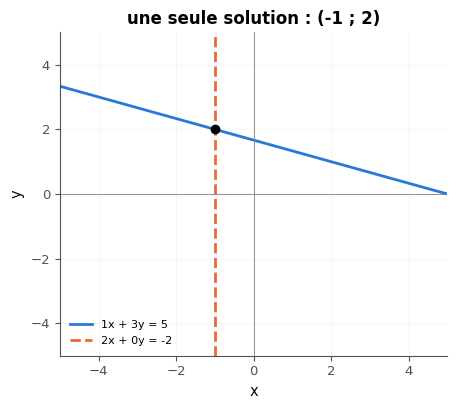

In [37]:
def plot_system(A, b, ax=None):
    """Draw the two lines of the system A·(x, y) = b, and their common point when there is exactly one."""
    own_figure = ax is None
    if own_figure:
        fig, ax = plt.subplots(figsize=(5, 4.2))
    xs = np.linspace(-5, 5, 200)
    for k, ((p, q), c) in enumerate(zip(A, b)):
        label = f"{p}x {'+' if q >= 0 else '−'} {abs(q)}y = {c}"
        style = "-" if k == 0 else "--"
        if q != 0:
            ax.plot(xs, (c - p * xs) / q, style, color=f"C{k}", label=label)
        else:
            ax.axvline(c / p, linestyle=style, color=f"C{k}", label=label)
    (a1, b1), (a2, b2) = A
    c1, c2 = b
    if a1 * b2 - b1 * a2 != 0:
        px, py = np.linalg.solve(np.array(A, dtype=float), np.array(b, dtype=float))
        ax.plot(px, py, "o", color="black", zorder=3)
        ax.set_title(f"une seule solution : ({px:g} ; {py:g})")
    elif a1 * c2 - a2 * c1 == 0 and b1 * c2 - b2 * c1 == 0:
        ax.set_title("une infinité de solutions (droites confondues)")
    else:
        ax.set_title("aucune solution (droites parallèles)")
    ax.axhline(0, color="gray", linewidth=0.6)
    ax.axvline(0, color="gray", linewidth=0.6)
    ax.set_xlim(-5, 5)
    ax.set_ylim(-5, 5)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8, loc="lower left")
    if own_figure:
        plt.show()


plot_system([[1, 3], [2, 0]], [5, -2])

**Vérifications automatiques** : les deux droites dans l'axe donné, un titre, et un système de déterminant nul qui ne fait pas planter la fonction.

In [38]:
with checked("R2.26 vérifications"):
    fig, axes = plt.subplots(1, 2)
    try:
        plot_system([[1, 3], [2, 0]], [5, -2], ax=axes[0])
        plot_system([[1, -3], [2, -6]], [3, 1], ax=axes[1])     # a zero determinant: no common point to mark
    finally:
        plt.close(fig)                                          # only the checks below are shown
    problems = []
    if any(len(ax.lines) < 2 for ax in axes):
        problems.append("trace les deux droites dans l'axe `ax` qu'on te donne, pas dans une nouvelle figure")
    if not all(ax.get_title() for ax in axes):
        problems.append("écris le titre avec `ax.set_title(...)`, sur l'axe donné")
    if problems:
        print("❌ Ex R2.26 : " + " ; ".join(problems) + ".")
    else:
        print("✅ Ex R2.26 : deux droites et un titre dans l'axe donné, y compris pour un déterminant nul.")

✅ Ex R2.26 : deux droites et un titre dans l'axe donné, y compris pour un déterminant nul.


💡 La seconde équation, $2x = -2$, ne contient pas $y$ : c'est la droite verticale $x = -1$. Le point commun est $(-1 \;;\; 2)$, et la substitution le confirme : $-1 + 3 \times 2 = 5$.

### Ex R2.24 — Prédire le nombre de solutions de trois systèmes, puis tracer leurs droites 🔮 ★ ⏱️ 15 min
**Objectif :** prévoir le nombre de solutions d'un système en regardant ses coefficients, puis le voir sur les droites.  
**Prérequis :** fiche §7 ; R2.26 (ta fonction `plot_system`) · **Parcours :** C, E

Trois systèmes :

$$S_1 : \begin{cases} 5x + y = 2 \\ 10x + 2y = 7 \end{cases} \qquad S_2 : \begin{cases} x + 2y = 4 \\ 3x - y = 5 \end{cases} \qquad S_3 : \begin{cases} 3x - 2y = 1 \\ -6x + 4y = -2 \end{cases}$$

**Avant d'exécuter quoi que ce soit**, et sans les résoudre, prédis le nombre de solutions de chacun : 1 pour aucune, 2 pour une seule, 3 pour une infinité. Regarde les coefficients de $x$ et de $y$ d'une équation à l'autre, puis les seconds membres (fiche §7). Écris tes trois prédictions, vérifie-les, puis lance l'expérience : elle calcule les trois déterminants et trace les trois systèmes avec ta fonction `plot_system` (R2.26).

In [39]:
# The three systems of R2.24: name -> (A, b), for a1·x + b1·y = c1, a2·x + b2·y = c2
SYSTEMS_24 = {
    "S1": ([[5, 1], [10, 2]], [2, 7]),
    "S2": ([[1, 2], [3, -1]], [4, 5]),
    "S3": ([[3, -2], [-6, 4]], [1, -2]),
}

In [40]:
wbm.record("R2.24a", 1, choices=[1, 2, 3], prediction=True,
           mistakes={"les coefficients sont proportionnels : compare aussi les seconds membres": 3,
                     "des coefficients proportionnels donnent un déterminant nul : pas une seule solution": 2})
wbm.record("R2.24b", 2, choices=[1, 2, 3], prediction=True,
           mistakes={"les coefficients ne sont pas proportionnels : les droites ne sont pas parallèles": 1,
                     "les coefficients ne sont pas proportionnels : les deux équations ne disent pas la même chose": 3})
wbm.record("R2.24c", 3, choices=[1, 2, 3], prediction=True,
           mistakes={"compare les seconds membres : sont-ils dans le même rapport que les coefficients ?": 1,
                     "des coefficients proportionnels donnent un déterminant nul : pas une seule solution": 2})

WBM_ANSWER {"choices": ["1", "2", "3"], "hash": "1ace0feb1a5d5f5abfaca8efc6e82e44a3b6f2b3d295ad8fab44dfbff44f8197", "id": "R2.24a", "kind": "int", "magnitude": 0, "mistakes": {"8c1490c3d003e1c4eee3acea5ba80726bac7b9d2a9130616e18842bb3917cb46": "des coefficients proportionnels donnent un déterminant nul : pas une seule solution", "e6f95309024601ee4502690a98ed7fe432d84c3f63678b8694a18fc6083de0a0": "les coefficients sont proportionnels : compare aussi les seconds membres"}, "prediction": true, "sign": 1}
📝 Ex R2.24a : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3"], "hash": "64de474482373d8683184a2e368cb2dd8635382c477727c1bc89ff7f3e76e718", "id": "R2.24b", "kind": "int", "magnitude": 0, "mistakes": {"cda25ac85f4ecd7b376dede9704c20044113735ad1864f1907852611ccc8f76a": "les coefficients ne sont pas proportionnels : les deux équations ne disent pas la même chose", "d2fbc08fddce06fe3924e06b4a6ea27a3f470012988bcd4ab13f94d3da3d0a29": "les coefficients ne sont pas proportionnels

**L'expérience.** Elle ne s'exécute qu'une fois tes trois prédictions écrites.

S1 : déterminant D = ad − bc = 0
S2 : déterminant D = ad − bc = -7
S3 : déterminant D = ad − bc = 0


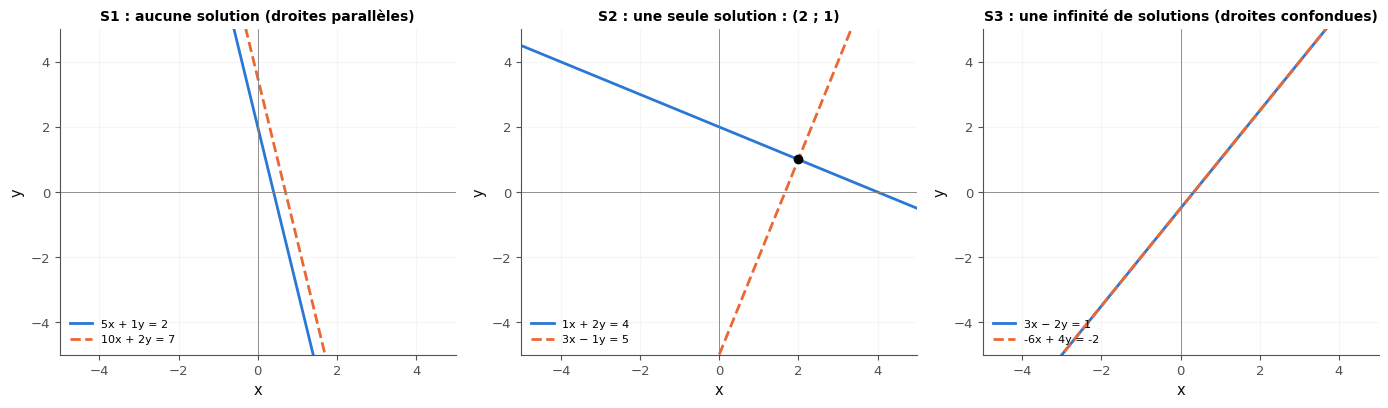

In [41]:
for name, (A, b) in SYSTEMS_24.items():
    (a1, b1), (a2, b2) = A
    print(f"{name} : déterminant D = ad − bc = {a1 * b2 - b1 * a2}")
with checked("R2.24 figure"):
    fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
    try:
        for ax, (name, (A, b)) in zip(axes, SYSTEMS_24.items()):
            plot_system(A, b, ax=ax)
            ax.set_title(f"{name} : {ax.get_title()}", fontsize=10)
    except BaseException:
        plt.close(fig)                       # no empty figure while plot_system is not written yet
        raise
    fig.tight_layout()
    plt.show()

💡 Dans $S_1$, la seconde équation a les coefficients de la première multipliés par 2, mais pas son second membre ($2 \times 2 \ne 7$) : deux droites parallèles. Dans $S_3$, tout est multiplié par $-2$, second membre compris : la même droite. Seul $S_2$ a des coefficients non proportionnels, donc un déterminant non nul ($-7$) et une seule solution, $(2 \;;\; 1)$.

### Ex R2.25 — Expérience : un système presque dégénéré, un coefficient bouge de 0,001 et la solution s'envole 🔬 ★★ ⏱️ 20 min
**Objectif :** voir qu'un système de déterminant presque nul est très sensible à ses coefficients.  
**Prérequis :** fiche §7 ; R2.24 · **Parcours :** C

On étudie le système $\begin{cases} x + y = 2 \\ x + c\,y = 2{,}001 \end{cases}$ pour des valeurs de $c$ proches de 1. Ses deux droites sont presque parallèles.

- Écris `solve_near(c)` : la solution `[x, y]`, calculée avec `np.linalg.solve`.
- a) Sa solution pour $c = 1{,}001$.
- b) Sa solution pour $c = 1{,}002$ : le coefficient n'a bougé que de 0,001.
- c) Son déterminant pour $c = 1{,}001$ (calcule-le dans ta tête, puis en Python).
- d) La valeur de $y$ pour $c = 1{,}0001$.

Puis lance l'expérience : elle trace $y$ en fonction de $c - 1$, de $10^{-4}$ à $10^{-2}$, sur deux échelles logarithmiques. Dans ta copie, dis en une phrase ce que la courbe montre, et pourquoi un déterminant presque nul est un signal d'alarme.

In [42]:
def solve_near(c):
    """Solution [x, y] of x + y = 2, x + c·y = 2.001 (with np.linalg.solve)."""
    return list(np.linalg.solve(np.array([[1, 1], [1, c]], dtype=float), np.array([2, 2.001])))


for c in (1.001, 1.002, 1.0001):
    print(f"c = {c} : (x, y) = ({solve_near(c)[0]:.6g}, {solve_near(c)[1]:.6g}) ; déterminant = {c - 1:.6g}")
answer_R2_25c = 1 * 1.001 - 1 * 1

c = 1.001 : (x, y) = (1, 1) ; déterminant = 0.001
c = 1.002 : (x, y) = (1.5, 0.5) ; déterminant = 0.002
c = 1.0001 : (x, y) = (-8, 10) ; déterminant = 0.0001


In [43]:
wbm.record("R2.25a", [1.0, 1.0], decimals=4,
           mistakes={"le second membre de la seconde équation est 2,001, pas 2": [2.0, 0.0]})
wbm.record("R2.25b", [1.5, 0.5], decimals=4,
           mistakes={"le coefficient c est celui de y dans la seconde équation, pas celui de x": [0.5, 1.5]})
wbm.record("R2.25c", 1.001 - 1, decimals=6,
           mistakes={"D = ad − bc : le produit de la diagonale moins l'autre produit, dans cet ordre": -0.001,
                     "D = ad − bc : n'oublie pas de soustraire le produit bc": 1.001})
wbm.record("R2.25d", 10.0, decimals=3)

WBM_ANSWER {"decimals": 4, "element_coarse": [["28d40fded342292fdbdb9133a0cbd11e3812099f848faa0188e097bef6b7c955"], ["351d33e32f77bde713123c09fc95db9d7403250981ed9923fa300769d680c80a"]], "element_hashes": ["ad1dd3abed62d72ae2b0c84e854ffcda19f30053d9e8b68697181ded5d9f0b1e", "addda5a1613bd092bfb49b60d6429fa83b4246898ccf18e4fe19e29860c3b444"], "hash": "6fc847ee03b831aeedcbfa6ee78648fd7269bce71d0a0a38cfcb15365a21559d", "id": "R2.25a", "kind": "array", "mistakes": {"bc84673e7bdc2d94738a2d913f9bbd4a02ea4826fb2b38af8549db982382f284": "le second membre de la seconde équation est 2,001, pas 2"}, "shape": [2]}
📝 Ex R2.25a : réponse enregistrée (array, 4 décimale(s)).
WBM_ANSWER {"decimals": 4, "element_coarse": [["f99e0073e58542c4dc2995697efd659c2dc00a3547134d487f70d60a47f032d5"], ["1a8fd3850cd7b7eab7e8f62057c6edfa49c3862f6e597b92843d3089e1c5aa93"]], "element_hashes": ["17945b82fb078f4778f085c15c5696b92708b50dcf71d6ba3aa294cd3d0dc181", "c2e4812c86ded2b07d2fa4c9f987269dc005804d7847b019a8e4c62eb0f

**L'expérience** : $y$ en fonction de $c - 1$.

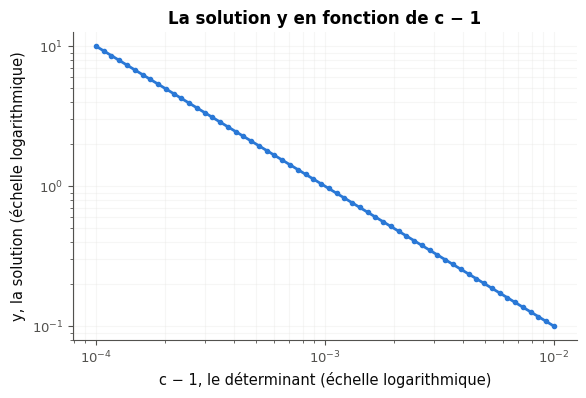

In [44]:
with checked("R2.25 figure"):
    gaps = np.logspace(-4, -2, 60)                    # c − 1, from 0.0001 to 0.01
    ys = [solve_near(1 + gap)[1] for gap in gaps]
    fig, ax = plt.subplots(figsize=(6.5, 4))
    ax.loglog(gaps, ys, "o-", markersize=3)
    ax.set_xlabel("c − 1, le déterminant (échelle logarithmique)")
    ax.set_ylabel("y, la solution (échelle logarithmique)")
    ax.set_title("La solution y en fonction de c − 1")
    ax.grid(True, which="both", alpha=0.3)
    plt.show()

💡 Un coefficient qui bouge de 0,001 (une erreur de mesure, un arrondi) fait passer $y$ de 1 à 0,5 : le système est **mal conditionné**. Ici $y = \frac{0{,}001}{c - 1}$ : diviser par un déterminant minuscule amplifie la moindre erreur. Sur la figure, la droite de pente −1 en échelles logarithmiques le dit : $y$ est multiplié par 10 quand $c - 1$ est divisé par 10. Le chapitre 9 de workbookIA parle du **conditionnement** d'un problème de moindres carrés, et des colonnes redondantes qui le dégradent.

## ✅ Bilan

**Auto-évaluation** (note-toi de 0 à 3 dans `mon_travail/suivi/auto_evaluation.md`) :
1. Développes-tu et factorises-tu sans erreur de signe, identités remarquables comprises, et vérifies-tu ton résultat (valeur test ou SymPy) ?
2. Résous-tu une équation ou une inéquation du premier degré, une équation produit nul et une valeur absolue, en écrivant l'ensemble des solutions (intervalles compris) ?
3. Résous-tu un système 2 × 2 de trois façons, et sais-tu dire, avec le déterminant, s'il a une seule solution ?

**La suite** : R3, *Fonctions*. Dans workbookIA, continue le chapitre 0A au rythme de ton tableau de bord.